# Part 3: Outlier Detection

**Author:** Mio Diaz <br>
**Purpose:** Mid-Report 2 

The assignment asks for all of the following:

| # | Assignment item | Where in this notebook |
|---|---|---|
| a | Apply at least two outlier detection methods | Section 4 DBSCAN, Section 5 One-Class SVM |
| b | Clearly define what an "outlier" is in our project context | Section 2 |
| c | Visualize detected outliers and explain their characteristics | Section 6, Section 7 |
| d | Discuss potential causes (data errors, rare but valid cases, automation, ...) | Section 8 |
| e | Evaluate the impact of outliers on clustering and dimensionality reduction | Section 9 |
| — | Robustness of the definition (not required) | Section 10 |
| — | Feed Section 4 (integration, insights, limitations) | Section 11 |

**Data:** Table A (`data/merged_dataset.csv`, 62,627 repos × 49 columns), 2024 GH Archive activity only. `inactive_next_365d` (2025) is never a feature; it is only used to *check* the outliers afterwards.

## Thought process at a glance

| Step | Question | Answer |
|---|---|---|
| 1. Normal (Section 2) | What does a maintained project look like? | The full data is dominated by one-burst repos, so we use **real projects** (≥ 3 active months, 7,890 repos). |
| 2. Definition (Section 2f) | What is an outlier? | *Hypothesis:* far from the maintained middle on either side. *Revised:* **abnormal activity** (very large, automated, odd mix); decay is common, so it is not an outlier. |
| 3. Features (Section 3) | How do we measure "far"? | 14 log-scaled, standardized 2024 activity features, including H1 vs H2. |
| 4. Methods (Sections 4–5) | Two ideas of "far" | **DBSCAN:** in an empty region. **One-Class SVM:** outside the boundary of normal. |
| 5. Types (Section 6) | Do they agree? What kinds? | Partial agreement (52 both, 209 either); six interpretable types. |
| 6. Visuals (Section 7) | What do they look like? | On the outer edges of the activity space; each type has its own profile; only "stopped in H2" decays (82% vs 47%). |
| 7. Causes (Section 8) | Why are they outliers? | TODO |
| 8. Impact (Section 9) | Do outliers change clustering / PCA? | TODO |
| 9. Robustness (Section 10) | Does the cutoff matter? | TODO |


## Glossary

Every term used in this notebook, defined once.

**GitHub and the data**

| Term | Meaning |
|---|---|
| repository (repo) | A project on GitHub: its code plus history. One row of the data. |
| open source / maintained | Public code anyone can use or improve. *Maintained* = someone keeps fixing, answering and releasing. |
| event / GH Archive | Every public action on GitHub is logged as an event; GH Archive is the public record of all of them. We count each repo's events in **2024**. |
| push | Uploading new code (commits). |
| issue / issue comment | A public ticket (bug, question, request) / a comment on an issue or PR. |
| pull request (PR) / review | A proposed code change / someone approving or requesting changes on a PR. |
| engagement | issues + issue comments + PRs + reviews: people interacting with the project. |
| release | A formally published version (e.g. v1.2.0). |
| star / fork | A bookmark or "like" / a copy of the repo made to build on it. |
| actor (contributor) | A GitHub account that did anything on the repo; bots count too. |
| active day / month | A day / month of 2024 with at least one event. |
| H1 / H2 | January–June / July–December 2024. |
| qualifying (maintenance) event | push, issue, comment, PR, review or release (not stars or forks). |
| real project / one-burst repo | Active in ≥ 3 / in 1–2 months of 2024 (Section 2d). |
| went quiet | A real project with no maintenance events in H2. |
| `inactive_next_365d` | 1 = no maintenance event at all in 2025. **Validation only, never a feature.** |

**Statistics**

| Term | Meaning |
|---|---|
| median / p*N* | Middle value / value that *N*% of repos are at or below (p99 = start of the top 1%). |
| skew | Lopsidedness: 0 = symmetric, > 1 = long right tail, > 10 = extreme. |
| `log1p(x)` | log(1 + x): compares by ratio (10 vs 100 = 100 vs 1,000); 0 stays 0. |
| z-score (standardized) | (value − mean) / standard deviation: 0 = average, +2 = far above, beyond ±3 = rare. |

**Outlier methods**

| Term | Meaning |
|---|---|
| global / collective outlier | Unusual vs the whole data / a group that is unusual together (e.g. many generated repos). (Lesson 11.2) |
| DBSCAN `eps`, `min_samples` | Neighbourhood radius / points needed inside it to count as crowded. |
| core / border / noise point | Crowded / next to a crowded point / neither = **DBSCAN outlier**. |
| k-distance | Distance from a point to its *k*-th nearest neighbour; used to choose `eps`. |
| One-Class SVM | Learns one boundary ("fence") around normal data; outside = outlier. |
| support vectors | The points sitting on the boundary that define it. |
| `nu` / `gamma` | ≈ share allowed outside / how tightly the boundary hugs the data. |
| decision score | Signed distance to the boundary: < 0 = outlier. |
| consensus / Jaccard | Flagged by both methods / overlap = both ÷ at least one (0–1). |


## 1. Setup: imports, shared constants and helpers

Everything reused later is defined once here; what each piece does and where it is used is in the code comments.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

DATA = Path("../data")
FIG_DIR = Path("../figures")
REPORT_IMG = Path("../report/img")
REPORT_IMG.mkdir(parents=True, exist_ok=True)

# Plot palette: one main hue, one highlight, recessive ink and grid.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"

# Feature groups (2024 GH Archive only). Single source of truth for every later step.
VOLUME = ["push_events_2024", "issue_events_2024", "issue_comment_events_2024", "pull_request_events_2024",
          "review_events_2024", "release_events_2024", "stars_received_2024", "fork_events_2024"]
BREADTH = ["distinct_actors_2024", "active_days_2024", "active_months_2024"]
ENGAGEMENT = ["issue_events_2024", "issue_comment_events_2024", "pull_request_events_2024", "review_events_2024"]
TREND = ["qualifying_events_h1_2024", "qualifying_events_h2_2024"]   # separate counts: the H2/H1 ratio is undefined when H1 = 0
RECENCY = ["days_since_last_push_at_cutoff"]                         # NaN = no push in 2024 -> 366
FEATURES = VOLUME + BREADTH + TREND + RECENCY
COUNTS = VOLUME + BREADTH + TREND                                    # columns that get log1p
LABEL = "inactive_next_365d"                                         # validation only, never a feature
MIN_MONTHS = 3                                                       # "real project" cutoff (Section 2e)


def real_projects(df, min_months=MIN_MONTHS):
    """Population filter: repos active in at least `min_months` separate months of 2024. Used in Sections 2, 10."""
    return df[df["active_months_2024"] >= min_months].copy()


def build_features(df):
    """Feature matrix: log1p on counts, NaN days-since-push -> 366, then standardize. Used in Sections 3, 9, 10."""
    raw = df[FEATURES].copy()
    raw[COUNTS] = np.log1p(raw[COUNTS])
    raw[RECENCY] = raw[RECENCY].fillna(366)
    return pd.DataFrame(StandardScaler().fit_transform(raw), index=df.index, columns=FEATURES)


def describe(df, quantiles=(0.01, 0.25, 0.5, 0.75, 0.99)):
    """Descriptive statistics table: mean, chosen quantiles, max, % zero, skew. Used in Section 2."""
    t = pd.DataFrame({"mean": df.mean()})
    for q in quantiles:
        t["median" if q == 0.5 else f"p{round(q * 100)}"] = df.quantile(q)
    t["max"] = df.max()
    t["% zero"] = (df == 0).mean() * 100
    t["skew"] = df.skew()
    return t.round(2)


def style(ax, grid="y"):
    """Recessive axes: no top/right spines, light grid on one axis (grid=None: no grid), muted ticks."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def short(col):
    """Readable feature label for charts: drop the _2024 / _events suffixes."""
    return (col.replace("_at_cutoff", "").replace("_2024", "").replace("qualifying_events_", "events ")
            .replace("_events", "").replace("_", " "))


def title(ax, text):
    """Left-aligned chart title."""
    ax.set_title(text, loc="left", fontsize=10, color=INK)


def save_fig(fig, name):
    """figures/<name>.svg (no timestamp -> clean diffs) and report/img/<name>.png."""
    fig.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight", metadata={"Date": None})
    fig.savefig(REPORT_IMG / f"{name}.png", bbox_inches="tight", dpi=150)


def outlier_summary(is_out, y, quiet):
    """Summary row for one outlier flag set (Sections 4, 5, 6, 10); y (2025 label) and quiet (no H2 events) are validation only."""
    return {"outliers": int(is_out.sum()), "% outliers": is_out.mean() * 100,
            "inactive rate (outliers)": y[is_out].mean(), "inactive rate (inliers)": y[~is_out].mean(),
            "% of quiet projects flagged": is_out[quiet].mean() * 100}


def plot_profile(X, is_out, method, name):
    """Profile chart: median z of each feature, inliers vs outliers (0 = population average). Used in Sections 4, 5."""
    prof = pd.DataFrame({"inliers": X[~is_out].median(), f"{method} outliers": X[is_out].median()})
    rows = np.arange(len(prof))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(rows + 0.2, prof.iloc[:, 0], height=0.4, color=GRID, label=prof.columns[0])
    ax.barh(rows - 0.2, prof.iloc[:, 1], height=0.4, color=BLUE, label=prof.columns[1])
    ax.set_yticks(rows, prof.index)
    ax.invert_yaxis()
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_xlabel("median standardized value (z)", color=MUTED)
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    title(ax, f"{method} outliers vs inliers: median of each feature")
    style(ax, grid="x")
    save_fig(fig, name)
    plt.show()
    return prof.round(2)


A = pd.read_csv(DATA / "merged_dataset.csv")
print(f"Table A: {len(A):,} repos x {A.shape[1]} columns | {len(FEATURES)} features")

Table A: 62,627 repos x 49 columns | 14 features


## 2. What counts as normal, and what counts as an outlier

**Question:** Before calling anything abnormal, what does a normal repo look like and is that the right reference for *maintained*?

**Approach:**
- 2a–2c: describe the **full population** and show why it can't be the reference.
- 2d: decide where a **real project** starts (active months).
- 2e: describe the **real-project population**; its dense middle is *normal*.
- 2f: write the definition.

### 2a. The full population: descriptive statistics

All 62,627 repos, one row per feature (terms: Glossary).

| Column | Meaning |
|---|---|
| mean / 50% | Average / median (the typical repo). Mean ≫ median = a few giant repos pull the average up. |
| 75% / 90% / 99% | Percentiles: the share of repos at or below this value. |
| max / % zero | The largest repo / share of repos with exactly 0. |
| skew | 0 = symmetric; > 10 = extremely lopsided. |

In [2]:
describe(A[VOLUME + BREADTH + RECENCY], quantiles=(0.5, 0.75, 0.9, 0.99))

,mean,median,p75,p90,p99,max,% zero,skew
push_events_2024,43.77,3.0,14.0,35.0,301.00,362071.0,1.91,136.80
issue_events_2024,1.61,0.0,0.0,0.0,13.00,51240.0,95.41,248.46
issue_comment_events_2024,2.41,0.0,0.0,0.0,27.00,30312.0,93.83,216.38
pull_request_events_2024,3.60,0.0,0.0,2.0,67.00,6209.0,84.62,69.51
review_events_2024,2.08,0.0,0.0,0.0,15.74,9237.0,97.23,79.89
release_events_2024,0.25,0.0,0.0,0.0,4.00,361.0,97.09,45.88
stars_received_2024,1.84,0.0,0.0,0.0,12.00,8745.0,90.41,96.29
fork_events_2024,0.40,0.0,0.0,0.0,4.00,1653.0,94.88,90.32
distinct_actors_2024,1.54,1.0,1.0,2.0,7.00,1251.0,0.00,86.88
active_days_2024,6.82,1.0,4.0,12.0,103.00,366.0,0.00,9.81


**Notes:**

- **What it shows:**

| Feature | Median | p99 | Max | % zero | Reading |
|---|---|---|---|---|---|
| pushes | 3 | 301 | 362,071 | 1.9% | Mean 43.8 ≫ median: a few huge, automated repos (`sslam1234/statslamgamedata`, ~1,000 pushes/day). |
| issues | 0 | 13 | 51,240 | 95.4% | 19 in 20 repos never use issues. |
| issue comments | 0 | 27 | 30,312 | 93.8% | Max: `adguardteam/adguardfilters`, a crowd-maintained filter list. |
| PRs | 0 | 67 | 6,209 | 84.6% | The most common collaboration, still rare. |
| reviews | 0 | ≈ 16 | 9,237 | 97.2% | Needs a second person. |
| releases | 0 | 4 | 361 | 97.1% | Almost no formal versions. |
| stars | 0 | 12 | 8,745 | 90.4% | 9 in 10 repos got no attention. |
| forks | 0 | 4 | 1,653 | 94.9% | Rarely copied. |
| actors | 1 | 7 | 1,251 | 0% | Most repos are one person. |
| active days | 1 | 103 | 366 | 0% | The typical repo was touched on one day. |
| active months | 1 | 12 | 12 | 0% | p90 = 3: only ~10% reach 3 months. |
| days since last push | 90 | 334 | 366 | – | Roughly symmetric (skew 0.96); the 1,198 repos with no push are left out. |

- **Takeaway:** the median repo is tiny (3 pushes, 1 person, 1 day, no community), and every count is extremely skewed (skew 46–248), so counts are log-transformed (2c) and the reference population is narrowed (2d–2e).

### 2b. The typical repo profile

Share of all repos meeting each "tiny repo" condition. Orange = all three of: 1 person, 1 month, no community activity.

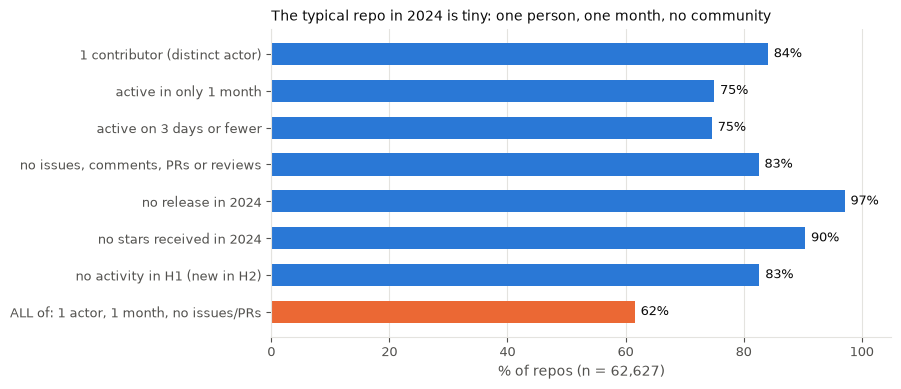

In [3]:
no_engagement = A[ENGAGEMENT].sum(axis=1).eq(0)
one_actor, one_month = A["distinct_actors_2024"].eq(1), A["active_months_2024"].eq(1)
profile = pd.Series({
    "1 contributor (distinct actor)": one_actor.mean(),
    "active in only 1 month": one_month.mean(),
    "active on 3 days or fewer": A["active_days_2024"].le(3).mean(),
    "no issues, comments, PRs or reviews": no_engagement.mean(),
    "no release in 2024": A["release_events_2024"].eq(0).mean(),
    "no stars received in 2024": A["stars_received_2024"].eq(0).mean(),
    "no activity in H1 (new in H2)": A["h1_qualifying_events_zero"].eq(1).mean(),
    "ALL of: 1 actor, 1 month, no issues/PRs": (one_actor & one_month & no_engagement).mean(),
}).mul(100)[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(profile.index, profile.values, color=[ORANGE] + [BLUE] * (len(profile) - 1), height=0.6)
for y, v in enumerate(profile.values):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set(xlim=(0, 105))
ax.set_xlabel(f"% of repos (n = {len(A):,})", color=MUTED)
title(ax, "The typical repo in 2024 is tiny: one person, one month, no community")
style(ax, grid="x")
save_fig(fig, "outliers_normal_profile")
plt.show()

**Notes:**

- **What it shows:** 84% of repos have one contributor, 75% were active in one month, and **62% are one person, one month, no community activity**. 83% had no H1 activity, mostly because they were created in H2.
- **Takeaway:** in the full data, *normal* = a short solo burst (homework, experiment, backup). Every maintained project would look like an outlier, the opposite of what we need.

### 2c. Why everything is log-transformed

The same data (pushes per repo) on a raw scale (left; y-axis log scale) and after `log1p` (right).

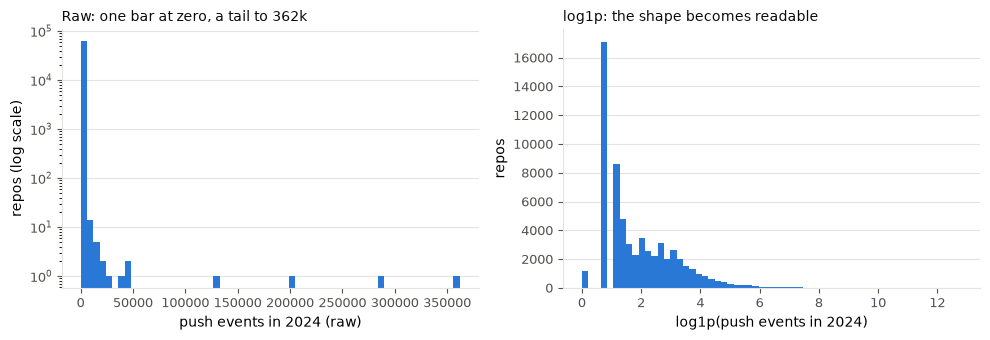

In [4]:
x = A["push_events_2024"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, values, xlabel, ylog, text in [
    (axes[0], x, "push events in 2024 (raw)", True, "Raw: one bar at zero, a tail to 362k"),
    (axes[1], np.log1p(x), "log1p(push events in 2024)", False, "log1p: the shape becomes readable"),
]:
    ax.hist(values, bins=60, color=BLUE)
    ax.set(xlabel=xlabel, ylabel="repos (log scale)" if ylog else "repos", yscale="log" if ylog else "linear")
    title(ax, text)
    style(ax)
fig.tight_layout()
save_fig(fig, "outliers_push_raw_vs_log")
plt.show()

**Notes:**

- **What it shows:**

| Panel | What you see |
|---|---|
| Raw | The first bar (0 to ~6,000 pushes) holds **99.95%** of repos; 3 and 3,000 pushes look the same. |
| `log1p` | Repos spread over 0–12.8; peak at 0–2.5 (≈ 0–11 pushes, 71% of repos); large repos still on the right, but not infinitely far. |

- **Takeaway:** distance-based methods on raw counts would just rank repos by size. With `log1p` + standardizing (Section 3), unusual *proportions* and *combinations* can be detected. Days since last push stays unlogged (bounded, symmetric).

### 2d. Where a "real project" starts

Repos by active months in 2024 (left, log scale) and their 2025 inactive rate (right). Blue = kept (≥ 3 months). The cutoff is a domain choice ("someone came back in ≥ 3 separate months"), not tuned on the label.

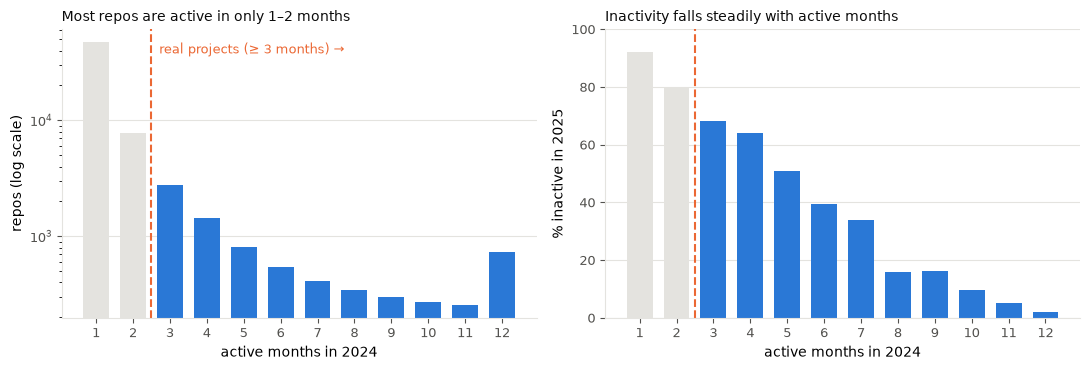

active_months_2024,1,2,3,4,5,6,7,8,9,10,11,12
repos,46973.00,7764.0,2775.00,1453.00,807.00,540.0,408.00,348.00,297.00,271.0,257.00,734.00
inactive_rate,0.92,0.8,0.68,0.64,0.51,0.4,0.34,0.16,0.16,0.1,0.05,0.02


In [5]:
by_month = A.groupby("active_months_2024")[LABEL].agg(repos="size", inactive_rate="mean")
months = by_month.index.to_numpy()
colors = np.where(months >= MIN_MONTHS, BLUE, GRID)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, values, ylabel, text in [
    (axes[0], by_month["repos"], "repos (log scale)", "Most repos are active in only 1–2 months"),
    (axes[1], by_month["inactive_rate"] * 100, "% inactive in 2025", "Inactivity falls steadily with active months"),
]:
    ax.bar(months, values, color=colors, width=0.7)
    ax.set(xlabel="active months in 2024", ylabel=ylabel, xticks=months)
    ax.axvline(MIN_MONTHS - 0.5, color=ORANGE, linestyle="--", linewidth=1.5)
    title(ax, text)
    style(ax)
axes[0].set_yscale("log")
axes[1].set_ylim(0, 100)
axes[0].text(MIN_MONTHS - 0.4, by_month["repos"].max(), f" real projects (≥ {MIN_MONTHS} months) →", color=ORANGE, fontsize=9, va="top")
fig.tight_layout()
save_fig(fig, "outliers_population_cutoff")
plt.show()
by_month.round(2).T

**Notes:**

- **What it shows:**

| Active months | Repos | Inactive in 2025 | Reading |
|---|---|---|---|
| 1–2 | 54,737 | 80–92% | One-off bursts, never maintained: **excluded** |
| 3–5 | 5,035 | 51–68% | Kept: someone came back; about half are abandoned |
| 6–11 | 2,121 | 5–40% | Most survive |
| 12 | 734 | 2% | Bigger than 9–11: busy projects plus always-on automation (first hint of high-side outliers) |

- **Takeaway:** inactivity falls almost steadily with active months (92% → 2%). ≥ 6 months is rerun in Section 10 to check the cutoff does not drive the results.

### 2e. The real-project population

Three outputs: (1) population split, (2) descriptive statistics for real projects (columns as in 2a, plus p1 and p25), (3) tails chart (solid = median, dotted = p1, dashed = p99).

In [6]:
P = real_projects(A)
group = np.select([A["active_months_2024"] >= 6, A["active_months_2024"] >= MIN_MONTHS],
                  ["real project, ≥ 6 months (robustness set, Section 10)", "real project, 3–5 months"],
                  default="one-burst repo, 1–2 months (excluded)")
split = A.groupby(group)[LABEL].agg(repos="size", inactive_rate="mean")
split["% of repos"] = split["repos"] / len(A) * 100
display(split.round(2))
print(f"Real-project population P: {len(P):,} repos ({len(P) / len(A):.1%}), inactive rate {P[LABEL].mean():.2f}")
describe(P[FEATURES])

,repos,inactive_rate,% of repos
"one-burst repo, 1–2 months (excluded)",54737,0.90,87.40
"real project, 3–5 months",5035,0.64,8.04
"real project, ≥ 6 months (robustness set, Section 10)",2855,0.18,4.56


Real-project population P: 7,890 repos (12.6%), inactive rate 0.47


,mean,p1,p25,median,p75,p99,max,% zero,skew
push_events_2024,214.05,0.89,19.0,37.0,83.00,1781.44,362071.0,1.00,71.93
issue_events_2024,11.74,0.00,0.0,0.0,0.00,111.33,51240.0,81.90,88.22
issue_comment_events_2024,18.09,0.00,0.0,0.0,1.00,289.11,30312.0,72.86,77.06
pull_request_events_2024,22.78,0.00,0.0,0.0,10.00,385.55,6209.0,59.10,25.84
review_events_2024,15.40,0.00,0.0,0.0,0.00,276.11,9237.0,86.89,28.77
release_events_2024,1.62,0.00,0.0,0.0,0.00,28.00,361.0,88.95,16.93
stars_received_2024,12.68,0.00,0.0,0.0,1.00,233.11,8745.0,71.80,34.80
fork_events_2024,2.54,0.00,0.0,0.0,0.00,45.00,1653.0,81.10,34.71
distinct_actors_2024,4.08,1.00,1.0,1.0,2.75,44.00,1251.0,0.00,31.53
active_days_2024,38.37,3.00,9.0,17.0,34.00,365.00,366.0,0.00,3.53


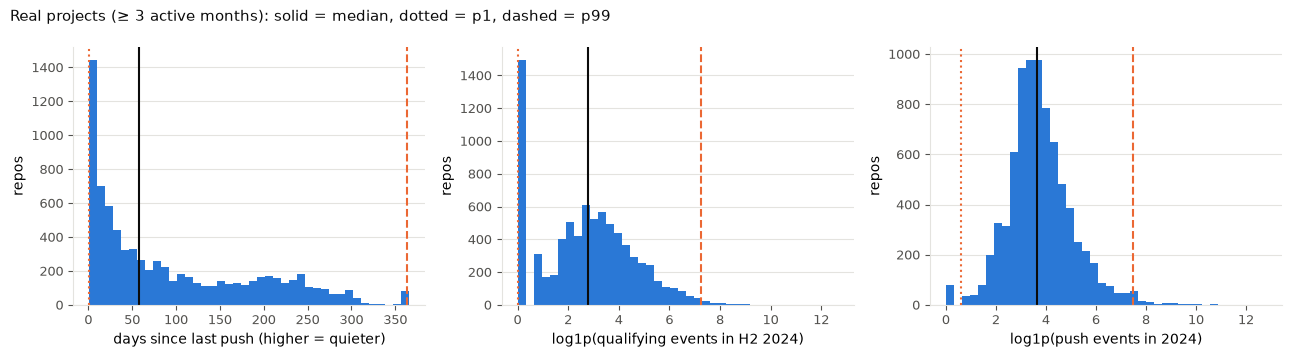

In [7]:
# Both tails inside the real-project population: low side (went quiet) and high side (huge volume).
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, xlabel in [
    (axes[0], "days_since_last_push_at_cutoff", "days since last push (higher = quieter)"),
    (axes[1], "qualifying_events_h2_2024", "log1p(qualifying events in H2 2024)"),
    (axes[2], "push_events_2024", "log1p(push events in 2024)"),
]:
    v = P[col].fillna(366)
    v = v if col in RECENCY else np.log1p(v)
    ax.hist(v, bins=40, color=BLUE)
    for q, ls, color in [(0.01, ":", ORANGE), (0.5, "-", INK), (0.99, "--", ORANGE)]:
        ax.axvline(v.quantile(q), color=color, linestyle=ls, linewidth=1.5)
    ax.set(xlabel=xlabel, ylabel="repos")
    style(ax)
fig.suptitle(f"Real projects (≥ {MIN_MONTHS} active months): solid = median, dotted = p1, dashed = p99",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
save_fig(fig, "outliers_project_tails")
plt.show()

**Notes:**

- **Split:** 87.4% one-burst (excluded, 90% inactive); 8.0% real 3–5 months (64%); 4.6% real ≥ 6 months (18%). **Real projects: 7,890 repos (12.6%), 47% inactive**, a mix of lasting and decaying projects.
- **All repos vs real projects:**

| Feature | All repos (median) | Real projects (median) | Real projects % zero |
|---|---|---|---|
| pushes | 3 | 37 | 1% |
| PRs | 0 | 0 (p75 = 10) | 59% |
| issues | 0 | 0 | 82% |
| actors | 1 | 1 (p75 ≈ 3) | – |
| active days | 1 | 17 | – |
| active months | 1 | 4 | – |
| H1 / H2 events | – | 26 / 15 | 29% / **19%** (1,497 went quiet) |
| days since last push | 90 | 58 | – |

- **Tails chart:**

| Panel | p1 | Median | p99 | Tail |
|---|---|---|---|---|
| days since last push | 1 | 58 | ≈ 363 | right = low-activity side |
| H2 events (`log1p`) | 0 | 15 | ≈ 1,381 | tall bar at 0 = 1,497 quiet projects |
| pushes (`log1p`) | ≈ 1 | 37 | ≈ 1,781 | right = bulk / automated pushers |

- **Takeaway:** a *normal* real project is a solo maintainer coming back 1–2 days a month. Both tails exist, but the low side is large (1 in 5), a first hint that decay is too common to be an outlier.

### 2f. Definition

**Initial hypothesis (before running any method):**

> Within real projects (≥ 3 active months in 2024), an outlier is a repo whose 2024 activity profile is far from the consistently-maintained middle, on the log scale, in either direction: **low side** = decaying (active, then went quiet), **high side** = abnormal volume (automation, bots, mirrors, very large projects).

**What the methods showed (Sections 4–5):** DBSCAN and One-Class SVM both put the projects that went quiet in H2 **inside** the normal region (0.9% and 1.5% of them flagged), and their outliers go inactive in 2025 *less* often than the population (20% and 28% vs 47%). Decay is too common to be an outlier: about **1 in 5** real projects went quiet in H2.

**Revised definition (used from Section 6 on):**

> **Within real projects, an outlier is a repo whose 2024 activity is abnormal compared with a consistently maintained project: unusually large, automated, or an unusual mix of activity. Decay is not an outlier in this data; it is a common pattern, which clustering is better placed to describe.**

- **Types (Lesson 11.2):** mostly **global** outliers (very large projects, bulk automation); **collective** outliers also appear (farms of generated repos with lorem-ipsum names, many near-identical classroom repos).
- **Expected share:** about 1–2% (One-Class SVM `nu = 0.01`; DBSCAN's share follows from `eps`).
- **Validation (not used for detection):** 2025 inactivity by outlier type (Section 6). Only the small "stopped in H2" type should look like decay.

### **Notes for the report:**
- **Population:** the full data is dominated by one-burst repos (median: 3 pushes, 1 person, 1 day), so it cannot be the reference for *maintained*. Outliers are detected among **real projects** (≥ 3 active months: 7,890 repos, 12.6%, 47% inactive in 2025); one-burst repos (87%, 90% inactive) are reported as a separate, never-maintained group.
- **Normal:** a solo maintainer who keeps coming back (median 37 pushes, 17 active days over 4 months, last push ~2 months before the cutoff).
- **Definition:** report both the hypothesis (outliers on either side) and the revision after Sections 4–5 (abnormal activity; decay is common, so a pattern for clustering). This shows the definition was tested, not assumed.
- **Method rules:** counts are log-transformed (otherwise outlier = biggest); the 2025 label is never used to detect, only to check.

## 3. Feature matrix

**Question:** How do we turn each real project into a point, so that "far from normal" can be measured?

| Choice | Why |
|---|---|
| Population `P` (7,890 real projects) | Section 2 |
| `log1p` on counts | Extreme skew (Section 2c) |
| Days since last push: missing → 366 | No push in the whole year |
| `StandardScaler` (z-scores) | No feature dominates because of its units |
| H1 and H2 events as separate features | A project that went quiet differs from a steady one with the same yearly total |
| **Not used:** identifiers; deps.dev / Scorecard values; flags like `has_package`; the 2025 label | 98–100% missing; a rare 1 standardizes to z ≈ 8 and dominates; label is validation only |

**How to read the output:** a shape line, then mean / std / min / max of each standardized feature. Mean 0 and std 1 check the scaling; **min and max** show how far the most extreme project sits from average (beyond ±3 is rare).

In [8]:
X = build_features(P)
y = P[LABEL]                                   # validation only
quiet = P["qualifying_events_h2_2024"].eq(0)  # 'went quiet': no qualifying events in H2 2024 (validation only)

assert not X.isna().any().any(), "NaN in feature matrix"
assert LABEL not in X.columns and "has_package" not in X.columns
print(f"X: {X.shape[0]:,} real projects x {X.shape[1]} features | went quiet in H2: {quiet.sum():,} ({quiet.mean():.0%})")
X.describe().loc[["mean", "std", "min", "max"]].round(2)

X: 7,890 real projects x 14 features | went quiet in H2: 1,497 (19%)


,push_events_2024,issue_events_2024,issue_comment_events_2024,pull_request_events_2024,review_events_2024,release_events_2024,stars_received_2024,fork_events_2024,distinct_actors_2024,active_days_2024,active_months_2024,qualifying_events_h1_2024,qualifying_events_h2_2024,days_since_last_push_at_cutoff
mean,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.86,-0.40,-0.50,-0.71,-0.33,-0.30,-0.45,-0.38,-0.60,-1.66,-0.99,-1.40,-1.42,-1.02
max,6.92,9.99,7.05,4.52,7.46,8.17,7.66,9.43,8.99,2.86,1.87,3.93,5.24,2.90


**Notes:**

- **What it shows:** `X` = 7,890 projects × 14 features, no missing values, every mean 0 and std 1.

| Feature | Min z (who) | Max z (who) | Reading |
|---|---|---|---|
| pushes | −2.86 (0 pushes) | 6.92 (`sslam1234/statslamgamedata`) | Zero pushes is unusual for a real project |
| issues | −0.40 (0) | **9.99** (`adguardteam/adguardfilters`) | Zero is typical; the top is extreme |
| issue comments | −0.50 | 7.05 (`adguardteam/adguardfilters`) | |
| PRs | −0.71 | 4.52 (`navikt/pensjon-etterlatte-saksbehandling`) | Least extreme count: 41% of projects have PRs |
| reviews | −0.33 | 7.46 (`navikt/…`) | |
| releases | −0.30 | 8.17 (`nrrogers/fork-wow-details-damage-meter`, 361 releases) | ~1 release a day: automated |
| stars | −0.45 | 7.66 (`lukasz-madon/awesome-remote-job`) | |
| forks | −0.38 | 9.43 (`argoproj/argocd-example-apps`) | Example repo people copy |
| actors | −0.60 (1 person) | 8.99 (1,251 people) | |
| active days | −1.66 (3 days) | 2.86 (366 days) | Capped, so never extreme |
| active months | −0.99 (3) | 1.87 (12) | Cannot make an outlier alone |
| H1 events | −1.40 (0) | 3.93 | |
| H2 events | −1.42 (0 = went quiet) | 5.24 | Quiet projects only −1.4: **not extreme** |
| days since last push | −1.02 (1 day) | 2.90 (366) | Fairly symmetric |

- **Takeaway:** even after the log, *low* is common (just below 0) and *high* can be 7–10 SD out, so the methods will mostly find **high-side** outliers. The same repos top several features (`adguardteam/adguardfilters`, `sslam1234/statslamgamedata`, `navikt/…`): global-outlier candidates.

### **Notes for the report:**
- Each real project is a point in 14 dimensions; "far from normal" = distance (DBSCAN) or outside a learned boundary (One-Class SVM).
- H1 and H2 are separate features so a project that went quiet differs from a steady one; the H2/H1 ratio is undefined for the 29% that started in H2.
- Left out on purpose: deps.dev / Scorecard values (98–100% missing), yes/no flags such as `has_package` (z ≈ 8), and the 2025 label (validation only).
- After standardizing, low activity is common and very high activity is extreme, so outliers are mainly high-side; projects that went quiet stay close to normal.

## 4. Method 1: DBSCAN noise points

**Question:** Which projects are not close to any dense group of projects?

Every project is a point with 14 coordinates (Section 3); similar projects are close. DBSCAN (Lesson 11.4) labels each point:

| Point | Rule | Meaning |
|---|---|---|
| core | ≥ `min_samples` points within `eps` | in a crowded area |
| border | within `eps` of a core point | at the edge of a crowd |
| noise (`-1`) | neither | **outlier**: in an empty region |

Outlier = *in an empty region*, not *the biggest value*. The toy example below shows both methods side by side (One-Class SVM: Section 5).

**Approach:** `min_samples` = 2 × features (lesson rule of thumb); `eps` from the k-distance knee; sensitivity to `eps`; `dbscan_labels` is reused in Section 10.

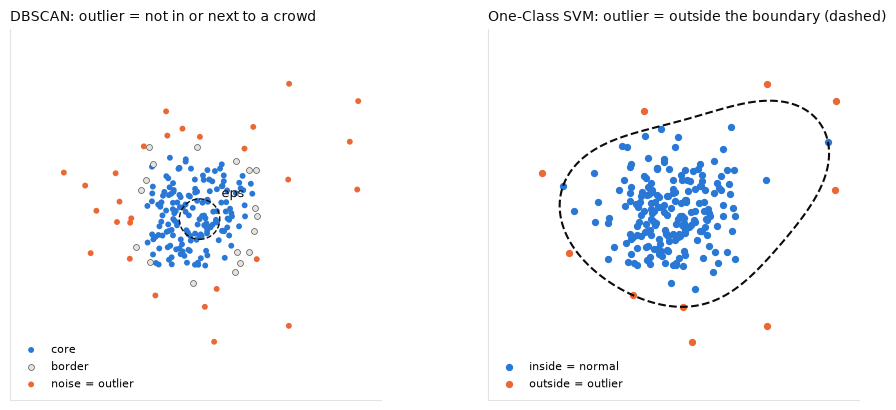

In [9]:
# Toy 2-D example (not our data): how each method decides what is "far".
rng = np.random.default_rng(0)
toy = np.vstack([rng.normal(0, 1, (200, 2)), rng.uniform(-5, 5, (12, 2))])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
db = DBSCAN(eps=0.6, min_samples=8).fit(toy)
core = np.zeros(len(toy), bool)
core[db.core_sample_indices_] = True
noise = db.labels_ == -1
for mask, color, label in [(core, BLUE, "core"), (~core & ~noise, GRID, "border"), (noise, ORANGE, "noise = outlier")]:
    axes[0].scatter(*toy[mask].T, s=18, color=color, edgecolor=MUTED if color == GRID else "none", linewidth=0.5, label=label)
axes[0].add_patch(plt.Circle(toy[np.argmax(core)], 0.6, fill=False, color=INK, linestyle="--"))
axes[0].annotate("eps", toy[np.argmax(core)] + 0.65, fontsize=9, color=INK)
title(axes[0], "DBSCAN: outlier = not in or next to a crowd")

svm = OneClassSVM(kernel="rbf", nu=0.05, gamma=0.05).fit(toy)
gx, gy = np.meshgrid(np.linspace(-5.5, 5.5, 300), np.linspace(-5.5, 5.5, 300))
zz = svm.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
axes[1].contour(gx, gy, zz, levels=[0], colors=INK, linestyles="--")
outside = svm.predict(toy) == -1
axes[1].scatter(*toy[~outside].T, s=18, color=BLUE, label="inside = normal")
axes[1].scatter(*toy[outside].T, s=18, color=ORANGE, label="outside = outlier")
title(axes[1], "One-Class SVM: outlier = outside the boundary (dashed)")
for ax in axes:
    ax.set(xlim=(-5.5, 5.5), ylim=(-5.5, 5.5), xticks=[], yticks=[], aspect="equal")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    style(ax, grid=None)
fig.tight_layout()
save_fig(fig, "outliers_methods_concept")
plt.show()

### 4a. Choosing `min_samples` and `eps`

`min_samples` = 2 × 14 = **28**. For `eps`: every project's distance to its 28th nearest neighbour (k-distance), sorted, is plotted; the **knee** (where the curve bends up) separates crowded from isolated projects. It is found as the point furthest below the straight line from the first to the last point (both axes scaled to 0–1), so it is not hand-picked.

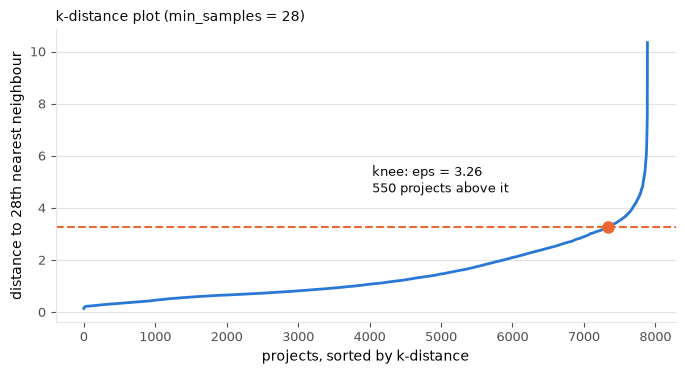

MIN_SAMPLES = 28, EPS = 3.26 (knee at the 93% point of the sorted curve)


In [10]:
MIN_SAMPLES = 2 * X.shape[1]

# kneighbors on the training data returns each point itself as neighbour 1 (distance 0),
# which matches DBSCAN counting the point itself towards min_samples.
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)
k_dist = np.sort(dist[:, -1])

x01 = np.linspace(0, 1, len(k_dist))
y01 = (k_dist - k_dist.min()) / (k_dist.max() - k_dist.min())
knee = int(np.argmax(x01 - y01))
EPS = round(float(k_dist[knee]), 2)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(len(k_dist)), k_dist, color=BLUE, linewidth=2)
ax.axhline(EPS, color=ORANGE, linestyle="--", linewidth=1.5)
ax.plot(knee, EPS, "o", color=ORANGE, markersize=8)
ax.annotate(f"knee: eps = {EPS}\n{len(k_dist) - knee:,} projects above it",
            (knee, EPS), xytext=(-170, 25), textcoords="offset points", fontsize=9, color=INK)
ax.set(xlabel="projects, sorted by k-distance", ylabel=f"distance to {MIN_SAMPLES}th nearest neighbour")
title(ax, f"k-distance plot (min_samples = {MIN_SAMPLES})")
style(ax)
save_fig(fig, "outliers_dbscan_kdistance")
plt.show()
print(f"MIN_SAMPLES = {MIN_SAMPLES}, EPS = {EPS} (knee at the {knee / len(k_dist):.0%} point of the sorted curve)")

**Notes:**

- **What it shows:**

| Part of the curve | Projects | k-distance | Meaning |
|---|---|---|---|
| flat (left 93%) | 7,340 | 0.13 – 3.26 (median 1.05) | crowded: 28 similar projects nearby |
| knee (orange) | – | **3.26 = `eps`** | where crowded turns into isolated |
| steep (right 7%) | 550 | 3.26 – 10.34 | isolated: candidates for noise |

### 4b. Fit and sensitivity to `eps`

Each row is one DBSCAN run. These columns are reused in Sections 5b and 6a:

| Column | Meaning |
|---|---|
| clusters / outliers / % outliers | Dense groups found / noise points / their share of 7,890 |
| inactive rate (outliers / inliers) | Share inactive in 2025 (all real projects: 0.47) |
| % of quiet projects flagged | Of the 1,497 projects that went quiet in H2, % flagged. High = outliers capture decay. |

The last three columns use information the method never saw; they only check *what kind* of project is flagged.

In [11]:
def dbscan_labels(X, eps, min_samples):
    """DBSCAN cluster labels as a Series aligned to X; -1 = noise = outlier."""
    return pd.Series(DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X), index=X.index)


labels = dbscan_labels(X, EPS, MIN_SAMPLES)
flags = pd.DataFrame(index=X.index)          # one boolean column per method, filled in Sections 4–5
flags["dbscan"] = labels.eq(-1)

rows = {}
for eps in sorted({2.0, 2.5, 3.0, EPS, 3.5, 4.0}):
    lab = labels if eps == EPS else dbscan_labels(X, eps, MIN_SAMPLES)
    rows[eps] = {"clusters": lab.max() + 1, **outlier_summary(lab.eq(-1), y, quiet)}
display(pd.DataFrame(rows).T.rename_axis("eps").round(2))
print(f"Chosen eps = {EPS}: {flags['dbscan'].sum()} outliers ({flags['dbscan'].mean():.1%}), "
      f"{labels.max() + 1} cluster(s); population inactive rate {y.mean():.2f}")

,clusters,outliers,% outliers,inactive rate (outliers),inactive rate (inliers),% of quiet projects flagged
eps,,,,,,
2.00,1.0,1384.0,17.54,0.21,0.53,7.62
2.50,1.0,732.0,9.28,0.16,0.51,2.94
3.00,1.0,287.0,3.64,0.19,0.49,1.54
3.26,1.0,148.0,1.88,0.20,0.48,0.94
3.50,1.0,75.0,0.95,0.15,0.48,0.33
4.00,1.0,33.0,0.42,0.21,0.48,0.20


Chosen eps = 3.26: 148 outliers (1.9%), 1 cluster(s); population inactive rate 0.47


**Notes:**

- **What it shows:**
  - The **count** depends strongly on `eps` (1,384 at 2.0 → 33 at 4.0); the **kind** does not: at every `eps` outliers are 15–21% inactive vs ~48% for inliers, and ≤ 7.6% of quiet projects are flagged.
  - Always **1 cluster**: real projects form one connected crowd plus stragglers.
  - At `eps` = 3.26: 7,336 core, 406 border, **148 noise (1.9%)**. Most of the 550 isolated projects from 4a are border points.

### 4c. What kind of projects did DBSCAN flag?

Median z-score per feature, inliers (grey) vs outliers (blue). 0 = average project; for rare features, −0.3 to −0.7 means **zero**; for days since last push, negative = more recent. The same chart is used in Section 5c.

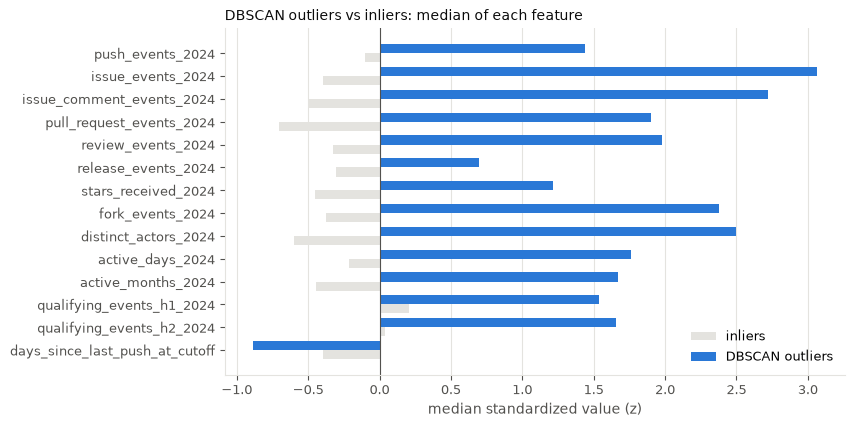

,inliers,DBSCAN outliers
push_events_2024,-0.10,1.44
issue_events_2024,-0.40,3.06
issue_comment_events_2024,-0.50,2.72
pull_request_events_2024,-0.71,1.90
review_events_2024,-0.33,1.98
release_events_2024,-0.30,0.69
stars_received_2024,-0.45,1.22
fork_events_2024,-0.38,2.37
distinct_actors_2024,-0.60,2.49
active_days_2024,-0.21,1.76


In [12]:
plot_profile(X, flags["dbscan"], "DBSCAN", "outliers_dbscan_profile")

**Notes:**

- **What it shows** (raw medians):

| Feature | Inliers | DBSCAN outliers |
|---|---|---|
| pushes | 36 | 277 |
| issues / comments | 0 / 0 | **36 / 81** |
| PRs / reviews | 0 / 0 | 78 / 14 |
| stars / forks / releases | 0 / 0 / 0 | 6 / 7 / 1 |
| contributors | 1 | **15** |
| active days / months | 16 / 4 | 122 / 11 |
| H1 / H2 events | 26 / 15 | 414 / 347 |
| days since last push | 59 | **13** |

- **Who:** busy community projects (`wagtail/wagtail`, `google/filament`, `github/advisory-database`, `tdlib/td`) plus ~17% with 1–2 contributors, mostly automation (`studio-arletti/uptime_monitor`, lorem-ipsum repos such as `taktikorg/doloremque-nemo`).
- **Not flagged:** `sslam1234/statslamgamedata` (362,071 pushes) is a *border* point: isolated, but within `eps` of a core point.

### **Notes for the report:**
- DBSCAN (`min_samples` = 28, `eps` = 3.26 from the k-distance knee) finds one dense cluster and **148 outliers (1.9%)**.
- All are **high side**: large, busy community projects and some automation. Only 20% went inactive in 2025 (vs 47%).
- The 1,497 projects that went quiet (86% inactive) are almost never flagged (0.9%): **decay is common, so it sits inside the crowd**; in a density-based method, common = normal. This connects to the clustering section.
- The outlier count is sensitive to `eps`, but the kind of outlier is not.

## 5. Method 2: One-Class SVM (Lesson 12.2, classification / boundary based)

**Question:** Which projects fall outside the learned boundary of a *normal* maintained project?

One-Class SVM (Lesson 12.2) draws one boundary around where most projects are, without labels; outside = outlier (toy example: Section 4, right panel).

| Setting | Value | Effect |
|---|---|---|
| kernel | RBF | Boundary can be curved |
| `nu` | 0.01 | ≈ share of projects left outside (expected ~1%, Section 2f) |
| `gamma` | `"scale"` = 1/14 ≈ 0.071 | How tightly the boundary hugs the data; too large overfits |

**Approach:** fit on all 7,890 projects; histogram of decision scores; `nu` × `gamma` sensitivity; `ocsvm_scores` is reused in Section 10.

### 5a. Fit and decision scores

Histogram of every project's decision score: **> 0** inside (larger = more typical), **0** on the boundary (orange line), **< 0** outlier.

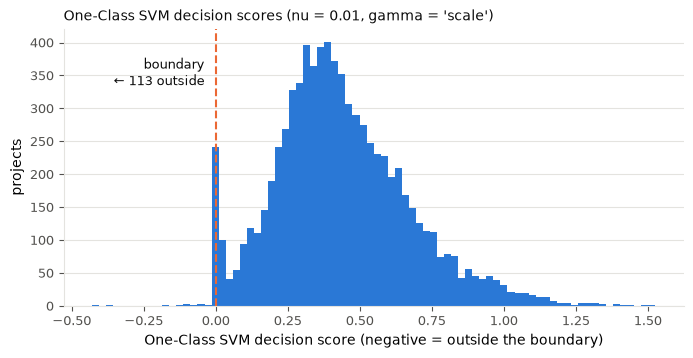

One-Class SVM: 113 outliers (1.4%); population inactive rate 0.47


In [13]:
NU, GAMMA = 0.01, "scale"


def ocsvm_scores(X, nu=NU, gamma=GAMMA):
    """One-Class SVM decision scores aligned to X; negative = outside the learned boundary = outlier."""
    model = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X)
    return pd.Series(model.decision_function(X), index=X.index)


scores = ocsvm_scores(X)
flags["ocsvm"] = scores.lt(0)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(scores, bins=80, color=BLUE)
ax.axvline(0, color=ORANGE, linestyle="--", linewidth=1.5)
ax.annotate(f"boundary\n← {flags['ocsvm'].sum()} outside", (0, ax.get_ylim()[1] * 0.9),
            xytext=(-8, 0), textcoords="offset points", fontsize=9, color=INK, va="top", ha="right")
ax.set(xlabel="One-Class SVM decision score (negative = outside the boundary)", ylabel="projects")
title(ax, f"One-Class SVM decision scores (nu = {NU}, gamma = {GAMMA!r})")
style(ax)
save_fig(fig, "outliers_ocsvm_scores")
plt.show()
print(f"One-Class SVM: {flags['ocsvm'].sum()} outliers ({flags['ocsvm'].mean():.1%}); population inactive rate {y.mean():.2f}")

**Notes:**

- **What it shows:**

| Region | Projects | Meaning |
|---|---|---|
| bulk (median 0.41, peak ≈ 0.39) | most | comfortably inside |
| spike at 0 | ≈ 240 | mostly the 218 support vectors that define the boundary |
| below 0 | **113 (1.4%)** | outliers; close to `nu` = 1% |

- **Most extreme:** `mate-academy/hibernate-configuration-hw` (−0.43: 215 contributors, 0 pushes), `adguardteam/adguardfilters` (−0.38). `sslam1234/statslamgamedata` is just below 0, so flagged here, unlike DBSCAN.

### 5b. Sensitivity to `nu` and `gamma`

One run per `nu` × `gamma`; columns as in 4b. If `nu` works, % outliers ≈ `nu` × 100.

In [14]:
rows = []
for nu in [0.01, 0.02, 0.05]:
    for gamma in [0.01, GAMMA, 0.3]:
        s = scores if (nu, gamma) == (NU, GAMMA) else ocsvm_scores(X, nu, gamma)
        rows.append({"nu": nu, "gamma": gamma, **outlier_summary(s.lt(0), y, quiet)})
pd.DataFrame(rows).round(2)

,nu,gamma,outliers,% outliers,inactive rate (outliers),inactive rate (inliers),% of quiet projects flagged
0,0.01,0.01,80,1.01,0.19,0.48,0.33
1,0.01,scale,113,1.43,0.28,0.48,1.47
2,0.01,0.3,654,8.29,0.30,0.49,6.55
3,0.02,0.01,158,2.00,0.20,0.48,0.94
4,0.02,scale,166,2.10,0.27,0.48,1.80
5,0.02,0.3,660,8.37,0.29,0.49,6.88
6,0.05,0.01,395,5.01,0.25,0.49,3.01
7,0.05,scale,403,5.11,0.26,0.49,3.67
8,0.05,0.3,623,7.90,0.26,0.49,5.48


**Notes:**

- **What it shows** (% outliers):

| `nu` \ `gamma` | 0.01 (loose) | `"scale"` | 0.3 (tight) |
|---|---|---|---|
| 0.01 | 1.0% | **1.4%** (chosen) | 8.3% |
| 0.02 | 2.0% | 2.1% | 8.4% |
| 0.05 | 5.0% | 5.1% | 7.9% |

- `nu` controls the share unless `gamma` is too large; at 0.3 ~8% are flagged whatever `nu` is (**overfitting**: the boundary wraps single points).
- In every run, outliers are 19–30% inactive vs 48–49% for inliers, and ≤ 7% of quiet projects are flagged.

### 5c. What kind of projects did One-Class SVM flag?

Same profile chart as 4c.

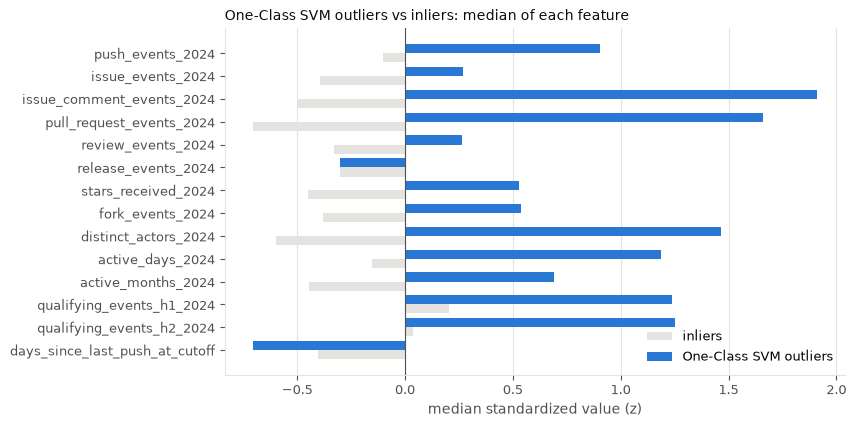

,inliers,One-Class SVM outliers
push_events_2024,-0.10,0.90
issue_events_2024,-0.40,0.27
issue_comment_events_2024,-0.50,1.91
pull_request_events_2024,-0.71,1.66
review_events_2024,-0.33,0.26
release_events_2024,-0.30,-0.30
stars_received_2024,-0.45,0.53
fork_events_2024,-0.38,0.54
distinct_actors_2024,-0.60,1.46
active_days_2024,-0.16,1.19


In [15]:
plot_profile(X, flags["ocsvm"], "One-Class SVM", "outliers_ocsvm_profile")

**Notes:**

- **What it shows** (raw medians):

| Feature | Inliers | One-Class SVM outliers | DBSCAN outliers (4c) |
|---|---|---|---|
| pushes | 36 | 137 | 277 |
| issues / comments | 0 / 0 | 1 / **26** | 36 / 81 |
| PRs / reviews | 0 / 0 | **51** / 1 | 78 / 14 |
| releases | 0 | **0** | 1 |
| contributors | 1 | 7 | 15 |
| active days / months | 17 / 4 | 68 / 7 | 122 / 11 |
| days since last push | 58 | 30 | 13 |

- Same direction as DBSCAN but about half as extreme: mid-sized projects with lots of discussion and PRs. **52 overlap** with DBSCAN; **61 found only here**, mostly odd mixes (14 outliers have 0 pushes despite heavy activity).
- **Who:** course repos where students submit PRs (`mate-academy/hibernate-configuration-hw`, `cmu-17313q/nodebb`, `scothann/prpracticerepo`), automation (`weiyilai/github-readme-stats`), giants also found by DBSCAN, and 22 projects with no H2 activity (e.g. `open-sauced/api`).

### **Notes for the report:**
- One-Class SVM (RBF, `nu` = 0.01, `gamma` = 1/14) flags **113 projects (1.4%)**; 28% went inactive in 2025 (vs 47%); only 1.5% of went-quiet projects are flagged.
- It confirms DBSCAN with a different idea of "far": outliers are mostly unusually active, and **decaying projects are inside the normal region**.
- It adds outliers DBSCAN mostly missed: odd *mixes* of activity (many contributors and PRs, no pushes), typical of classroom repos, possibly a **collective** outlier.
- `gamma` too large (0.3) overfits; `"scale"` is kept.

## 6. Do the two methods agree, and what kinds of outliers are there?

**Question:** Which repos are outliers under both ideas of "far", and what *kinds* of abnormal activity do they represent?

**Approach:** overlap and Jaccard (6a); **consensus** = flagged by both (most reliable; used in Sections 7–9), **any** = at least one (used for types); rule-based types (6b); example repos (6c, input for Section 8).

### 6a. Agreement

2 × 2 table: rows = DBSCAN, columns = One-Class SVM (`True` = outlier). Then counts, Jaccard (both ÷ at least one), and the summary columns of 4b for each set.

In [16]:
flags["consensus"] = flags["dbscan"] & flags["ocsvm"]
flags["any"] = flags["dbscan"] | flags["ocsvm"]
jaccard = flags["consensus"].sum() / flags["any"].sum()

display(pd.crosstab(flags["dbscan"], flags["ocsvm"], rownames=["DBSCAN outlier"],
                    colnames=["One-Class SVM outlier"], margins=True, margins_name="total"))
print(f"Both: {flags['consensus'].sum()} | DBSCAN only: {(flags['dbscan'] & ~flags['ocsvm']).sum()} | "
      f"One-Class SVM only: {(flags['ocsvm'] & ~flags['dbscan']).sum()} | at least one: {flags['any'].sum()} | Jaccard = {jaccard:.2f}")
pd.DataFrame({m: outlier_summary(flags[m], y, quiet) for m in ["dbscan", "ocsvm", "consensus", "any"]}).T.round(2)

One-Class SVM outlier,False,True,total
DBSCAN outlier,,,
False,7681,61,7742
True,96,52,148
total,7777,113,7890


Both: 52 | DBSCAN only: 96 | One-Class SVM only: 61 | at least one: 209 | Jaccard = 0.25


,outliers,% outliers,inactive rate (outliers),inactive rate (inliers),% of quiet projects flagged
dbscan,148.0,1.88,0.20,0.48,0.94
ocsvm,113.0,1.43,0.28,0.48,1.47
consensus,52.0,0.66,0.21,0.48,0.40
any,209.0,2.65,0.24,0.48,2.00


**Notes:**

- **What it shows:**

| | One-Class SVM: no | One-Class SVM: yes |
|---|---|---|
| **DBSCAN: no** | 7,681 normal | 61 outside the boundary only |
| **DBSCAN: yes** | 96 empty region only | **52 consensus** |

- **Jaccard = 0.25:** a shared core of obvious outliers, plus projects each method catches alone. Expected for two different ideas of "far".
- Every set (each method, consensus, any) goes inactive about **half as often** as inliers (20–28% vs 48%); the consensus flags only 6 of 1,497 quiet projects.

### 6b. Outlier types

Each of the 209 outliers gets one type from rules on raw 2024 counts, checked **in order (first match wins)**. Rules only *describe* outliers the methods found; they detect nothing.

| # | Type | Rule | In plain words |
|---|---|---|---|
| 1 | stopped in H2 | H1 > 0 and H2 ≤ 10% of H1 | dropped off sharply mid-year |
| 2 | activity without pushes | pushes < 20% of engagement | busy, but almost no code uploaded (classroom, ticket queue) |
| 3 | automation / bulk pushes | ≥ 250 active days and ≤ 2 people, or ≥ 500 pushes with engagement ≤ 5% of pushes and ≤ 5 people | something runs every day, or a script uploads in bulk |
| 4 | large community project | ≥ 10 people or ≥ 500 engagement | real, busy, collaborative |
| 5 | new in H2 with a burst | H1 = 0 | created mid-2024 and immediately busy |
| 6 | other mixed profile | none of the above | |

Chart: blue = DBSCAN only, orange = both, green = One-Class SVM only; label = total (2025 inactive rate).

found_by,DBSCAN only,both,One-Class SVM only,total,inactive rate
type,,,,,
large community project,39,16,10,65,0.06
activity without pushes,21,17,17,55,0.13
automation / bulk pushes,12,2,7,21,0.10
new in H2 with a burst,5,2,5,12,0.42
stopped in H2,11,11,16,38,0.82
other mixed profile,8,4,6,18,0.06


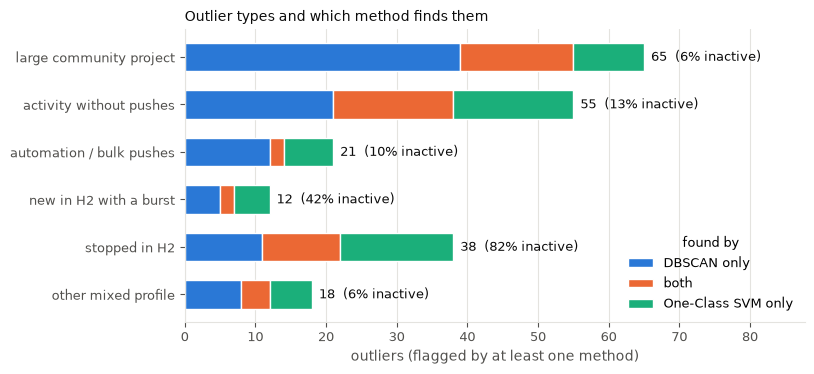

In [17]:
def outlier_type(df):
    """Rule-based type for each repo (first matching rule wins); thresholds are on raw 2024 counts."""
    push, actors, days = df["push_events_2024"], df["distinct_actors_2024"], df["active_days_2024"]
    eng = df[ENGAGEMENT].sum(axis=1)
    h1, h2 = df["qualifying_events_h1_2024"], df["qualifying_events_h2_2024"]
    rules = {
        "stopped in H2": (h1 > 0) & (h2 <= 0.1 * h1),
        "activity without pushes": push < 0.2 * (eng + 1),
        "automation / bulk pushes": ((days >= 250) & (actors <= 2)) | ((push >= 500) & (eng <= 0.05 * push) & (actors <= 5)),
        "large community project": (actors >= 10) | (eng >= 500),
        "new in H2 with a burst": h1 == 0,
    }
    return pd.Series(np.select(list(rules.values()), list(rules.keys()), default="other mixed profile"), index=df.index)


TYPE_ORDER = ["large community project", "activity without pushes", "automation / bulk pushes",
              "new in H2 with a burst", "stopped in H2", "other mixed profile"]
outliers = P[flags["any"]].assign(type=lambda d: pd.Categorical(outlier_type(d), TYPE_ORDER),
                                  found_by=np.select([flags["consensus"], flags["dbscan"]], ["both", "DBSCAN only"],
                                                     default="One-Class SVM only")[flags["any"]])
by_type = pd.crosstab(outliers["type"], outliers["found_by"])[["DBSCAN only", "both", "One-Class SVM only"]]
by_type["total"] = by_type.sum(axis=1)
by_type["inactive rate"] = outliers.groupby("type", observed=False)[LABEL].mean().round(2)
display(by_type)

fig, ax = plt.subplots(figsize=(8, 3.8))
left = np.zeros(len(by_type))
for col, color in zip(["DBSCAN only", "both", "One-Class SVM only"], [BLUE, ORANGE, "#1baf7a"]):
    ax.barh(by_type.index, by_type[col], left=left, color=color, height=0.6, label=col,
            edgecolor="white", linewidth=1)
    left += by_type[col].to_numpy()
for yy, (total, rate) in enumerate(zip(by_type["total"], by_type["inactive rate"])):
    ax.text(total + 1, yy, f"{total}  ({rate:.0%} inactive)", va="center", fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlim(0, by_type["total"].max() * 1.35)
ax.set_xlabel("outliers (flagged by at least one method)", color=MUTED)
ax.legend(frameon=False, fontsize=9, loc="lower right", title="found by", title_fontsize=9)
title(ax, "Outlier types and which method finds them")
style(ax, grid="x")
save_fig(fig, "outliers_types_by_method")
plt.show()

**Notes:**

- **What it shows:**
  - **Large community projects (65)** are mostly found by DBSCAN: extreme on many features at once. 6% inactive.
  - **Activity without pushes (55)** has the most consensus outliers (17): the odd *mix* stands out to both. 13% inactive.
  - **Automation (21)** is rarely found by both (2). 10% inactive: scripts keep running.
  - **Stopped in H2 (38)** is the **only** type above the 47% base rate: **82% inactive**. One-Class SVM finds slightly more (27 vs 22): a sharp drop is an unusual combination.
  - About two thirds (141 of 209) are healthy, busy projects or activity that is not human maintenance.

### 6c. Example repos per type

The 4 most extreme outliers of each type by One-Class SVM score (input for Section 8). Columns are 2024 counts (Glossary); engagement = issues + comments + PRs + reviews.

In [18]:
SHOW = ["repo_full_name", "found_by", "push_events_2024", "distinct_actors_2024", "active_days_2024",
        "qualifying_events_h1_2024", "qualifying_events_h2_2024", "stars_received_2024", LABEL]
examples = (outliers.assign(score=scores, engagement=outliers[ENGAGEMENT].sum(axis=1))
            .sort_values("score").groupby("type", observed=True).head(4)
            .sort_values(["type", "score"]))
examples[["type"] + SHOW[:3] + ["engagement"] + SHOW[3:]].set_index(["type", "repo_full_name"])

found_by  \
type                     repo_full_name                                                         
large community project  adguardteam/adguardfilters                                      both   
                         scothann/prpracticerepo                                         both   
                         navikt/pensjon-etterlatte-saksbehandling                        both   
                         soenneker/soenneker.cosmos.suite                                both   
activity without pushes  mate-academy/hibernate-configuration-hw                         both   
                         cmu-17313q/nodebb                                               both   
                         weiyilai/github-readme-stats                                    both   
                         manssur94/manssur-personal-tasks                                both   
automation / bulk pushes sslam1234/statslamgamedata                        One-Class SVM only   
                         tja4472/ngrx-task                                 One-Class SVM only   
                         rimim/duck_gym                                    One-Class SVM only   
                         fantasyworld123/rsshub                            One-Class SVM only   
new in H2 with a burst   avanade/approval-system                                         both   
                         vitonsky/arrival-time                             One-Class SVM only   
                         pjy02/v2ray-rules-dat                             One-Class SVM only   
                         pearl-image-comparer/pearl                                      both   
stopped in H2            open-sauced/api                                                 both   
                         animator/learn-python                                           both   
                         israfilalam22/custom_keycloak                     One-Class SVM only   
                         2lambda123/gping                                                both   
other mixed profile      cveproject/cvelist                                              both   
                         severecloud/arti                                  One-Class SVM only   
                         spring-financial-group/docker-credential-acr-env  One-Class SVM only   
                         arnesven/fatefuleight2                            One-Class SVM only   

                                                                           push_events_2024  \
type                     repo_full_name                                                       
large community project  adguardteam/adguardfilters                                   22260   
                         scothann/prpracticerepo                                        274   
                         navikt/pensjon-etterlatte-saksbehandling                      8478   
                         soenneker/soenneker.cosmos.suite                              3522   
activity without pushes  mate-academy/hibernate-configuration-hw                          0   
                         cmu-17313q/nodebb                                                2   
                         weiyilai/github-readme-stats                                     0   
                         manssur94/manssur-personal-tasks                                 0   
automation / bulk pushes sslam1234/statslamgamedata                                  362071   
                         tja4472/ngrx-task                                             1669   
                         rimim/duck_gym                                                8414   
                         fantasyworld123/rsshub                                         210   
new in H2 with a burst   avanade/approval-system                                        159   
                         vitonsky/arrival-time                                           50   
                         pjy02/v2ray-rules

**Notes:**

- **What it shows:**

| Type | Examples | Why they stand out |
|---|---|---|
| large community project | `adguardteam/adguardfilters`, `navikt/pensjon-etterlatte-saksbehandling`, `soenneker/soenneker.cosmos.suite`, `scothann/prpracticerepo` | 1,251 people and 85,625 engagement events; or a small team with very heavy PR traffic (likely partly bots); or 267 people in 24 days (a PR practice repo) |
| activity without pushes | `mate-academy/hibernate-configuration-hw`, `cmu-17313q/nodebb`, `weiyilai/github-readme-stats`, `manssur94/manssur-personal-tasks` | Course repos where students submit PRs (215 and 49 people, ~0 pushes); one-person repos used as task lists or driven by automation |
| automation / bulk pushes | `sslam1234/statslamgamedata`, `rimim/duck_gym`, `tja4472/ngrx-task`, `fantasyworld123/rsshub` | 362,071 / 8,414 pushes by 1 person, no engagement; daily scripts |
| new in H2 with a burst | `avanade/approval-system`, `vitonsky/arrival-time`, `pjy02/v2ray-rules-dat`, `pearl-image-comparer/pearl` | 0 H1 events, hundreds in H2; 2 of 4 inactive in 2025 |
| stopped in H2 | `open-sauced/api`, `israfilalam22/custom_keycloak`, `2lambda123/gping`, `animator/learn-python` | 2,359 → 0, 992 → 0, 452 → 0, 4,200 → 194 events; **all 4 inactive in 2025** |
| other mixed profile | `cveproject/cvelist`, `severecloud/arti`, … | e.g. the official vulnerability list: 7,766 pushes by 7 people; none inactive |

- **Collective outlier:** a farm of generated repos with lorem-ipsum (placeholder text) names (`erboladaiorg/deleniti-consequuntur-nostrum`, `taktikorg/doloremque-nemo`, `patrtorg/explicabo-atque-impedit`, …), each with ~1,700 pushes, 2 contributors and no engagement.

### **Notes for the report:**
- The two methods partly agree (52 consensus outliers, 209 in total, Jaccard 0.25); the consensus set is the most reliable.
- Outliers fall into a few interpretable types. Most are *healthy* (large, busy projects) or *not human maintenance* (automation, classroom activity); only the small "stopped in H2" type (38 projects, 82% inactive) looks like decay.
- The type rules are one-sentence thresholds on raw counts; they describe outliers, they do not detect them.

## 7. Visualizing the outliers and checking the definition

**Question:** What do the outliers look like compared with normal projects, and does the revised definition hold?

**Approach:**
- **7a** where outliers sit in a 2-D map of all projects (PCA; used here only as a viewing tool, the DR analysis itself is the DR section's);
- **7b** typical feature values per outlier type vs normal projects;
- **7c** 2025 inactivity per type vs the 47% base rate (validation only).

### 7a. Where are the outliers? (PCA map)

PCA squeezes the 14 features into 2 axes (PC1, PC2) that keep as much of the spread as possible. The loadings table says what each axis means (large positive = the feature pushes a project right / up). One panel per outlier type: grey = all real projects, blue = flagged by one method, orange = flagged by both. Caveat: 2 axes lose part of the information, so a point can look central here and still be far in 14-D.

,PC1,PC2
push,0.19,0.45
issue,0.31,-0.21
issue comment,0.34,-0.20
pull request,0.28,-0.09
review,0.28,-0.10
release,0.19,-0.06
stars received,0.28,-0.25
fork,0.30,-0.26
distinct actors,0.35,-0.22
active days,0.28,0.39


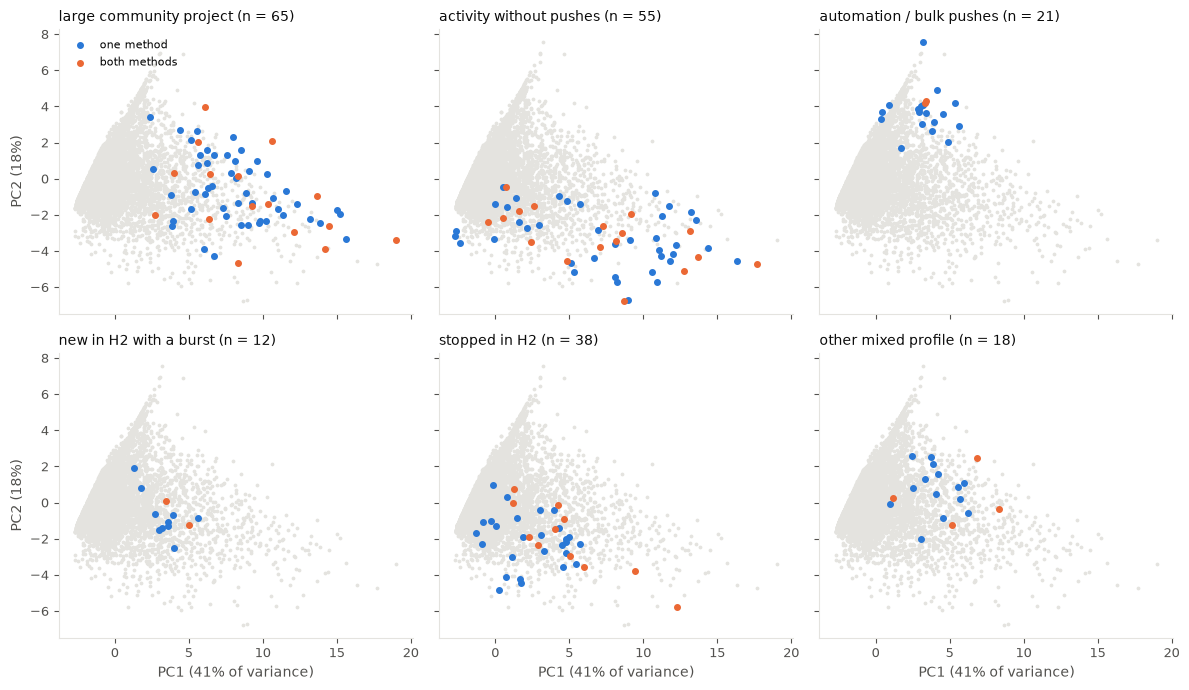

PC1 + PC2 keep 58% of the variance


In [19]:
pca = PCA(n_components=2).fit(X)
pc = pd.DataFrame(pca.transform(X), index=X.index, columns=["PC1", "PC2"])
pc_var = pca.explained_variance_ratio_
display(pd.DataFrame(pca.components_.T, index=[short(c) for c in X.columns], columns=["PC1", "PC2"]).round(2))

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
for ax, t in zip(axes.flat, TYPE_ORDER):
    sel = outliers.index[outliers["type"] == t]
    both = sel[flags.loc[sel, "consensus"]]
    ax.scatter(pc["PC1"], pc["PC2"], s=3, color=GRID)
    ax.scatter(*pc.loc[sel.difference(both)].T.to_numpy(), s=16, color=BLUE, label="one method")
    ax.scatter(*pc.loc[both].T.to_numpy(), s=16, color=ORANGE, label="both methods")
    title(ax, f"{t} (n = {len(sel)})")
    style(ax, grid=None)
for ax in axes[1]:
    ax.set_xlabel(f"PC1 ({pc_var[0]:.0%} of variance)", color=MUTED)
for ax in axes[:, 0]:
    ax.set_ylabel(f"PC2 ({pc_var[1]:.0%})", color=MUTED)
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
save_fig(fig, "outliers_pca_by_type")
plt.show()
print(f"PC1 + PC2 keep {pc_var.sum():.0%} of the variance")

### 7b. What does each type look like?

Median z-score of every feature per group (rows) — 0 = average real project, blue = below, red = above (Glossary: z-score). For rare features, about −0.3 to −0.7 means **zero**; for days since last push, red = quieter.

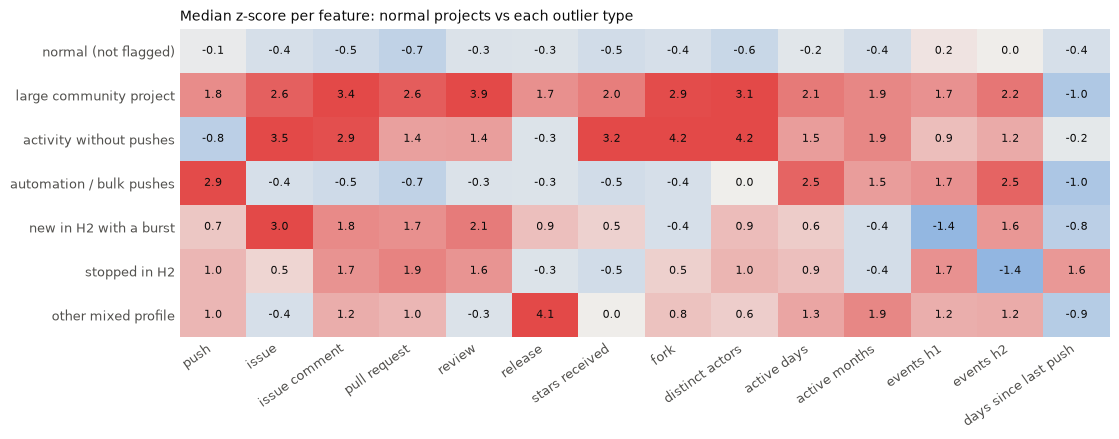

In [20]:
groups = pd.concat([X[~flags["any"]].median().rename("normal (not flagged)").to_frame().T,
                    X.loc[outliers.index].groupby(outliers["type"], observed=True).median()])
groups.columns = [short(c) for c in groups.columns]

cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(groups, cmap=cmap, vmin=-3, vmax=3, aspect="auto")
for (r, c), v in np.ndenumerate(groups.to_numpy()):
    ax.text(c, r, f"{v:.1f}", ha="center", va="center", fontsize=8, color=INK)
ax.set_xticks(range(groups.shape[1]), groups.columns, rotation=35, ha="right")
ax.set_yticks(range(len(groups)), groups.index)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
ax.spines[:].set_visible(False)
title(ax, "Median z-score per feature: normal projects vs each outlier type")
save_fig(fig, "outliers_type_heatmap")
plt.show()

### 7c. Does the definition hold? 2025 inactivity by type

Share of each group inactive in 2025 (validation only). Dashed line = all real projects (47%). Grey = normal projects (reference), orange = the only outlier type above the base rate.

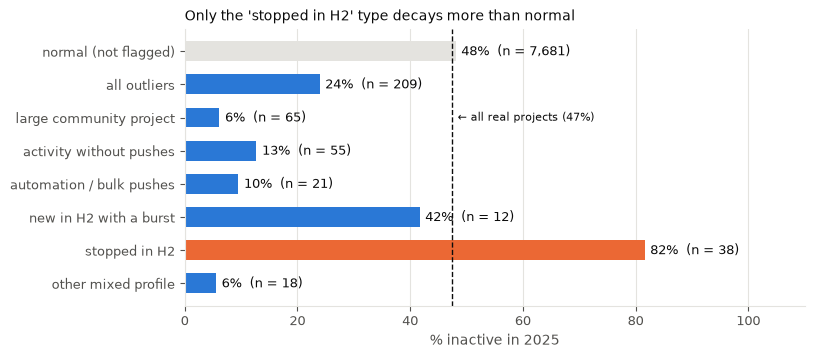

In [21]:
rate = pd.concat([
    pd.Series({"normal (not flagged)": y[~flags["any"]].mean(), "all outliers": y[flags["any"]].mean()}),
    outliers.groupby("type", observed=True)[LABEL].mean(),
])
n = pd.concat([pd.Series({"normal (not flagged)": (~flags["any"]).sum(), "all outliers": flags["any"].sum()}),
               outliers["type"].value_counts()])

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [GRID if k == "normal (not flagged)" else ORANGE if k == "stopped in H2" else BLUE for k in rate.index]
ax.barh(rate.index, rate * 100, color=colors, height=0.6)
ax.axvline(y.mean() * 100, color=INK, linestyle="--", linewidth=1)
ax.text(y.mean() * 100 + 1, 2, f"← all real projects ({y.mean():.0%})", fontsize=8, color=INK, va="center")
for yy, (k, v) in enumerate(rate.items()):
    ax.text(v * 100 + 1, yy, f"{v:.0%}  (n = {n[k]:,})", va="center", fontsize=9, color=INK)
ax.invert_yaxis()
ax.set(xlim=(0, 110))
ax.set_xlabel("% inactive in 2025", color=MUTED)
title(ax, "Only the 'stopped in H2' type decays more than normal")
style(ax, grid="x")
save_fig(fig, "outliers_inactivity_by_type")
plt.show()

**Notes:**

- **7a, PCA map** (PC1 + PC2 keep 58% of the variance):

| Axis | High values mean | Reading |
|---|---|---|
| PC1 (41%) | more of **everything** (all loadings positive) | overall activity: right = busier |
| PC2 (18%) | many pushes, active days, H2 events, recent push (up) vs issues, stars, forks, contributors (down) | up = **automated / solo**, down = **community** |

| Type | Where it sits |
|---|---|
| large community project | far right, middle: busy on everything |
| activity without pushes | right and **bottom**: community signals without pushes |
| automation / bulk pushes | **top**: pushes and daily activity, no community |
| new in H2 / other mixed | near the edge of the main cloud |
| stopped in H2 | lower edge of the cloud: no H2 activity, old last push |

  Outliers sit on the **right and outer edges** of the cloud, never in the dense left part where normal projects are.

- **7b, heatmap** (raw medians in brackets):

| Type | Stands out on | Low on |
|---|---|---|
| large community project | everything: comments, reviews, contributors (23), forks | days since last push (4) |
| activity without pushes | issues, contributors (50), forks (30), stars (61) | pushes (14) |
| automation / bulk pushes | pushes (1,985), active days (254), H2 events | all community features (0) |
| new in H2 with a burst | issues, reviews, H2 events | H1 events (0) |
| stopped in H2 | H1 events, PRs, days since last push (235) | H2 events (0) |
| other mixed profile | releases (21) | – |

  Each type has its own fingerprint, so the six types are not arbitrary labels.

- **7c, inactivity:** normal projects 48%; all outliers 24%; types 6–13% except **new in H2 (42%)** and **stopped in H2 (82%)**.

### **Notes for the report:**
- Outliers sit on the outer edges of the activity space (PCA), and each type has a clear profile: community-heavy, push-heavy (automation), or a sharp H1 → H2 drop.
- The revised definition holds: outliers go inactive half as often as normal projects (24% vs 48%). The only decay-like outliers are the 38 projects that **stopped abruptly** (82% inactive); ordinary decay is common and stays inside the normal region.
- PCA is used only as a viewing tool here; the DR analysis belongs to the DR section.

## 8. Potential causes

**Question:** Why are these repos outliers — real behaviour, automation, or data problems?

**Approach:**
- Read the names and profiles of the example outliers from Section 6c.
- Map each type to likely causes:
  - **large community project** → rare but valid;
  - **activity without pushes** → classroom / course repos, PR-driven workflows, mirrors;
  - **automation / bulk pushes** → bots, scrapers, generated or spam repos;
  - **new in H2 with a burst** → new project launch (valid) or bulk import;
  - **stopped in H2** → abandonment, finished project, or moved elsewhere;
  - any type → **data artifacts** (duplicate names, collection gaps).
- Count per cause.

In [22]:
# TODO: top outliers per side with names + assigned cause, counts per cause

**Notes:**

- **Assignment item:** Outlier Detection → discuss potential causes of these anomalies
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 9. Impact on clustering and dimensionality reduction

**Question:** If we keep vs remove the consensus outliers, do the clusters and the PCA picture change?

**Depends on the clustering and DR sections.** Until their settings are known, this section uses a baseline K-means + PCA; the settings block below is the only thing to swap. Share with the clustering and DR owners:

| Item | Value |
|---|---|
| Population | `real_projects(A)`: `active_months_2024 >= 3` (7,890 repos) |
| Features | `FEATURES` → `build_features` (Section 1); coverage flags and `inactive_next_365d` are **not** features |
| Finding for clustering | Decaying projects (went quiet, 1 in 5) are **not** sparse (Sections 4–5): expect them as a cluster, not as outliers |

**Open questions:**
- [ ] Clustering: algorithm and `k` / `eps` / `minPts`; same population and features? If DBSCAN, align `eps` / `minPts` with Section 4 (their noise points = our DBSCAN outliers).
- [ ] DR: PCA components kept; t-SNE / UMAP settings; same population and features?
- [ ] Do they want the outlier flags exported (`is_outlier`) to rerun without outliers?

**Approach:** fit K-means (`K` by silhouette) and PCA **with** and **without** the consensus outliers; compare PCA explained variance and loadings, cluster sizes, silhouette, centroid shift, and Adjusted Rand Index on the shared inliers; before / after figures.

In [23]:
# === Settings to replace with teammates' choices ===
K = None          # TODO: number of clusters (silhouette, or the clustering owner's k)
N_COMPONENTS = 2  # PCA components for plotting
# ====================================================
# TODO: fit K-means + PCA with / without consensus outliers, compare metrics

In [24]:
# TODO: before / after figures

**Notes:**

- **Assignment item:** Outlier Detection → evaluate the impact of outliers on clustering and dimensionality reduction
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 10. Robustness: a stricter population

**Question:** Does the result depend on where we drew the "real project" line?

**Approach:**
- Rerun the same pipeline on projects active ≥ 6 months (2,855 repos, 18% inactive): `build_features(real_projects(A, 6))` → `dbscan_labels` / `ocsvm_scores`.
- Compare: share of outliers, agreement, type mix, and whether decaying (went-quiet) projects are still inside the normal region.

In [25]:
# TODO: X6 = build_features(real_projects(A, 6)); rerun both methods; comparison table vs Sections 6–7

**Notes:**

- **Assignment item:** (robustness, not required) does the outlier definition hold for a stricter population?
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 11. Summary for the report

Report-ready bullets for Section 3, plus inputs for Section 4 (integration, insights, limitations, next steps).

**Notes:** (filled in as sections are completed)

| Topic | Result | Section |
|---|---|---|
| Population | **Real projects**: ≥ 3 active months, 7,890 repos (12.6%), 47% inactive in 2025. One-burst repos (87%, 90% inactive) were never maintained and are reported separately. | 2 |
| Definition | *Hypothesis:* far from the maintained middle on either side. *Revised:* **abnormal activity** (very large, automated, odd mix); decay is common (1 in 5) and is a pattern for clustering. | 2f |
| Features | 14 standardized 2024 activity features (`log1p` counts, H1 vs H2, days since last push); no package / Scorecard data, no 2025 label. | 3 |
| DBSCAN | `min_samples` 28, `eps` 3.26 (k-distance knee): 1 cluster + **148 outliers (1.9%)**, all high side; 20% inactive; 0.9% of quiet projects flagged. | 4 |
| One-Class SVM | `nu` 0.01, `gamma` 1/14: **113 outliers (1.4%)**; 28% inactive; 1.5% of quiet flagged; also finds odd mixes (classroom repos). `gamma` 0.3 overfits. | 5 |
| Agreement | 52 consensus, 209 total, Jaccard 0.25. | 6a |
| Types | large community 65 (6% inactive), activity without pushes 55 (13%), stopped in H2 38 (**82%**), automation 21 (10%, incl. a lorem-ipsum repo farm), other 18 (6%), new in H2 12 (42%). | 6b |
| Validation | All outliers 24% inactive vs 47%; only "stopped in H2" looks like decay. | 6 |
| Characteristics | Outliers sit on the outer edges of the PCA map (busier on PC1; automation up, community down on PC2); each type has a distinct feature profile (heatmap). | 7 |
| Causes | TODO | 8 |
| Impact on clustering / DR | TODO | 9 |
| Robustness (≥ 6 months) | TODO | 10 |
| Actionable insight | TODO | – |
| Limitations / next steps | One-burst repos excluded by design; two methods only (GMM / VAE not run); packaged projects not analysed; DBSCAN count sensitive to `eps` (type is not); TODO | – |